In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from collections import Counter

In [3]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None
    

In [4]:
class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=100, n_features=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_features = n_features
        self.root = None

    def fit(self, X, y):
        self.n_features = X.shape[1] if not self.n_features else min(X.shape[1], self.n_features)
        self.root = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))

        # check the stopping criteria
        if (depth >= self.max_depth or n_labels==1 or n_samples<self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        feat_idxs = np.random.choice(n_feats, self.n_features, replace=False)
        # find the best split
        best_feature, best_thresh = self._best_split(X, y, feat_idxs)

        # create child nodes
        left_idxs, right_idxs = self._split(X[:, best_feature], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth+1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth+1)
        return Node(best_feature, best_thresh, left, right)

    def _best_split(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_threshold = None, None

        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)

            for thr in thresholds:
                # calculate information gain
                gain = self._information_gain(y, X_column, thr)

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_threshold = thr

        return split_idx, split_threshold

    def _information_gain(self, y, X_column, threshold):
        # parent entropy
        parent_entropy = self._entropy(y)

        # create children
        left_idxs, right_idxs = self._split(X_column, threshold)

        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0

        # calculate the weighted avg entropy of children
        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = self._entropy(y[left_idxs]), self._entropy(y[right_idxs])
        child_entropy = (n_l/n) * e_l + (n_r/n) * e_r

        # calculate the Information Gain
        information_gain = parent_entropy - child_entropy
        return information_gain


    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _entropy(self, y):
        hist = np.bincount(y)
        ps = hist / len(y)
        return -np.sum([p * np.log(p) for p in ps if p>0])

    def _most_common_label(self, y):
        counter = Counter(y)
        most_common = counter.most_common(1)[0][0]
        return most_common

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right) 

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])


In [5]:
class RandomForest:
    def __init__(self, n_trees=10, max_depth=10, min_samples_split=2, n_features = None):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_features = n_features
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        for _ in range(self.n_trees):
            tree = DecisionTree(max_depth=self.max_depth, min_samples_split=self.min_samples_split,
            n_features=self.n_features)
            X_sample, y_sample = self._bootstrap_samples(X, y)
            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

    def _bootstrap_samples(self, X, y):
        n_samples = X.shape[0]
        idxs = np.random.choice(n_samples, n_samples, replace=True)
        return X[idxs], y[idxs]

    def _most_common_label(self, y):
        counter = Counter(y)
        most_common = counter.most_common(1)[0][0]
        return most_common

    def predict(self, X):
        predictions = np.array([tree.predict(X) for tree in self.trees])
        tree_preds = np.swapaxes(predictions, 0, 1)
        predictions = np.array([self._most_common_label(pred) for pred in tree_preds])
        return predictions



In [6]:
class RandomForestOOB(RandomForest):
    def fit(self, X, y):
        self.trees = []
        # Store votes for each sample: shape (n_samples, n_classes)
        self.oob_votes = np.zeros((X.shape[0], len(np.unique(y))))
        
        for _ in range(self.n_trees):
            tree = DecisionTree(max_depth=self.max_depth, min_samples_split=self.min_samples_split, n_features=self.n_features)
            n_samples = X.shape[0]
            # Bootstrap sample indices
            idxs = np.random.choice(n_samples, n_samples, replace=True)
            # Find the out-of-bag indices (those not in the bootstrap sample)
            oob_idxs = np.array(list(set(range(n_samples)) - set(idxs)))
            
            # Train the tree
            tree.fit(X[idxs], y[idxs])
            self.trees.append(tree)
            
            # Record OOB predictions
            if len(oob_idxs) > 0:
                preds = tree.predict(X[oob_idxs])
                for i, p in zip(oob_idxs, preds):
                    self.oob_votes[i, int(p)] += 1
                    
        # Calculate final OOB score
        oob_final_preds = np.argmax(self.oob_votes, axis=1)
        # Only evaluate on rows that were left out at least once
        was_oob = np.sum(self.oob_votes, axis=1) > 0
        self.oob_score_ = np.sum(y[was_oob] == oob_final_preds[was_oob]) / np.sum(was_oob)


In [9]:
data = datasets.load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

In [10]:
clf = RandomForest()
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)

In [11]:
# --- Execution ---
clf_oob = RandomForestOOB(n_trees=10, max_depth=10)
clf_oob.fit(X_train, y_train)
print(f"OOB Score: {clf_oob.oob_score_:.4f}")
print(f"Test Accuracy: {accuracy(y_test, clf_oob.predict(X_test)):.4f}")

OOB Score: 0.9401
Test Accuracy: 0.9211


In [7]:
def accuracy(y_true, y_pred):
    return np.sum(y_true == y_pred) / len(y_true)

In [12]:
acc = accuracy(y_test, predictions)
print(acc)

0.9385964912280702


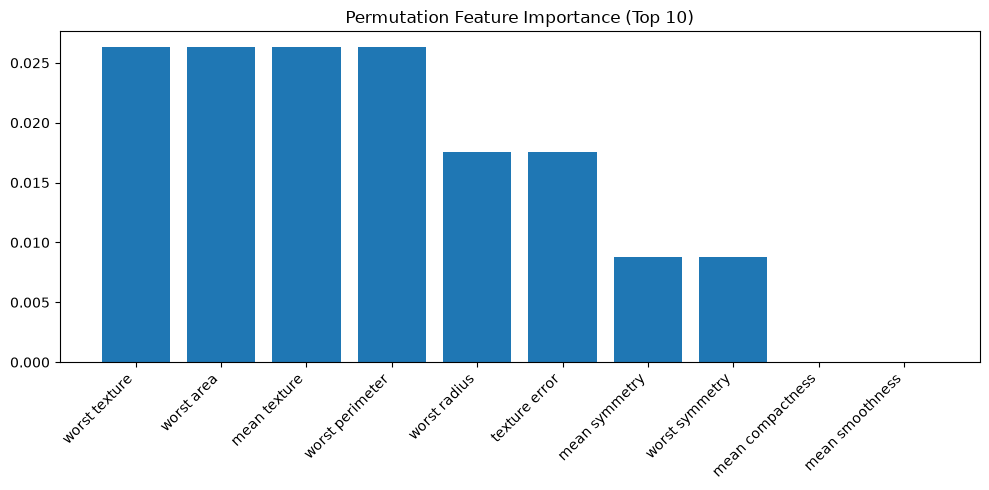

In [14]:
def permutation_importance(model, X, y, metric=accuracy):
    baseline_score = metric(y, model.predict(X))
    importances = []
    
    for i in range(X.shape[1]):
        X_permuted = X.copy()
        # Shuffle the current feature column
        np.random.shuffle(X_permuted[:, i])
        
        # Calculate new score with the corrupted feature
        permuted_score = metric(y, model.predict(X_permuted))
        
        # Importance is the drop in accuracy
        drop_in_score = baseline_score - permuted_score
        importances.append(drop_in_score)
        
    return np.array(importances)

# --- Execution ---
importances = permutation_importance(clf, X_test, y_test)

# Plotting the top 10 features
indices = np.argsort(importances)[::-1][:10]
plt.figure(figsize=(10, 5))
plt.title("Permutation Feature Importance (Top 10)")
plt.bar(range(10), importances[indices], align="center")
plt.xticks(range(10), [data.feature_names[i] for i in indices], rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [15]:
def tune_random_forest(X_train, y_train, X_val, y_val, param_grid):
    best_acc = 0
    best_params = {}
    best_model = None
    
    # Simple grid search loop
    for n_trees in param_grid['n_trees']:
        for max_depth in param_grid['max_depth']:
            for min_samples_split in param_grid['min_samples_split']:
                
                # Initialize and train using your original class
                model = RandomForest(n_trees=n_trees, 
                                     max_depth=max_depth, 
                                     min_samples_split=min_samples_split)
                model.fit(X_train, y_train)
                
                # Evaluate
                preds = model.predict(X_val)
                acc = accuracy(y_val, preds)
                
                print(f"Trained: n_trees={n_trees}, depth={max_depth}, split={min_samples_split} | Acc: {acc:.4f}")
                
                # Track best
                if acc > best_acc:
                    best_acc = acc
                    best_params = {
                        'n_trees': n_trees, 
                        'max_depth': max_depth, 
                        'min_samples_split': min_samples_split
                    }
                    best_model = model
                    
    return best_model, best_params, best_acc

# --- Execution ---
# We need a validation set for proper tuning to avoid overfitting the test set
X_train_tune, X_val, y_train_tune, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

param_grid = {
    'n_trees': [5, 10, 20],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

print("Starting tuning process...")
best_model, best_params, best_acc = tune_random_forest(
    X_train_tune, y_train_tune, X_val, y_val, param_grid
)

print("\n--- Tuning Results ---")
print(f"Best Parameters: {best_params}")
print(f"Validation Accuracy: {best_acc:.4f}")
print(f"Test Accuracy (Best Model): {accuracy(y_test, best_model.predict(X_test)):.4f}")

Starting tuning process...
Trained: n_trees=5, depth=5, split=2 | Acc: 0.9451
Trained: n_trees=5, depth=5, split=5 | Acc: 0.9231
Trained: n_trees=5, depth=5, split=10 | Acc: 0.9560
Trained: n_trees=5, depth=10, split=2 | Acc: 0.9670
Trained: n_trees=5, depth=10, split=5 | Acc: 0.9451
Trained: n_trees=5, depth=10, split=10 | Acc: 0.9451
Trained: n_trees=5, depth=15, split=2 | Acc: 0.9231
Trained: n_trees=5, depth=15, split=5 | Acc: 0.9341
Trained: n_trees=5, depth=15, split=10 | Acc: 0.9560
Trained: n_trees=10, depth=5, split=2 | Acc: 0.9451
Trained: n_trees=10, depth=5, split=5 | Acc: 0.9670
Trained: n_trees=10, depth=5, split=10 | Acc: 0.9560
Trained: n_trees=10, depth=10, split=2 | Acc: 0.9451
Trained: n_trees=10, depth=10, split=5 | Acc: 0.9451
Trained: n_trees=10, depth=10, split=10 | Acc: 0.9780
Trained: n_trees=10, depth=15, split=2 | Acc: 0.9451
Trained: n_trees=10, depth=15, split=5 | Acc: 0.9560
Trained: n_trees=10, depth=15, split=10 | Acc: 0.9670
Trained: n_trees=20, depth=5

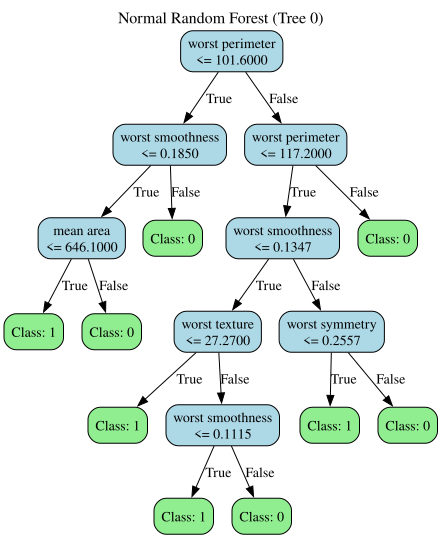

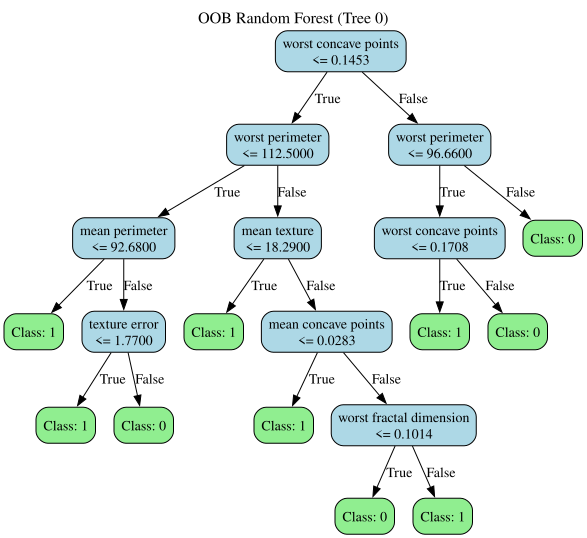

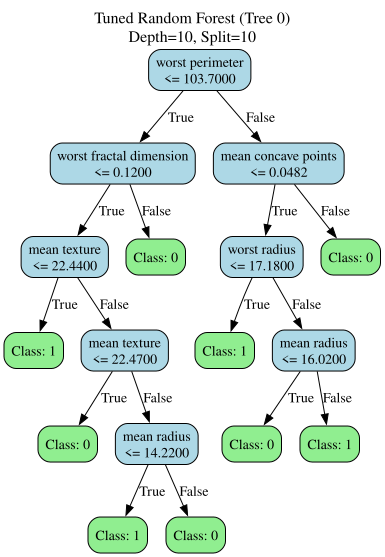

In [17]:
import graphviz
from IPython.display import display, HTML

def visualize_custom_tree(tree_model, feature_names=None, title="Decision Tree"):
    """Recursively converts a custom DecisionTree into a Graphviz Digraph."""
    dot = graphviz.Digraph(name=title, node_attr={'shape': 'box', 'style': 'rounded,filled'})
    dot.attr(label=title, labelloc='t', fontsize='16')
    
    def add_nodes_edges(node, parent_id=None, edge_label=""):
        # Use the memory address as a unique ID for each node
        node_id = str(id(node))
        
        if node.is_leaf_node():
            # Leaf node formatting
            label = f"Class: {node.value}"
            dot.node(node_id, label, fillcolor="#90EE90") # Light green
        else:
            # Decision node formatting - Fixed the boolean evaluation here
            feat_name = feature_names[node.feature] if feature_names is not None else f"Feature {node.feature}"
            label = f"{feat_name}\n<= {node.threshold:.4f}"
            dot.node(node_id, label, fillcolor="#ADD8E6") # Light blue
            
            # Recurse for children
            add_nodes_edges(node.left, node_id, "True")
            add_nodes_edges(node.right, node_id, "False")
            
        if parent_id is not None:
            dot.edge(parent_id, node_id, label=edge_label)
            
    if tree_model.root is not None:
        add_nodes_edges(tree_model.root)
        
    return dot

# --- Execution & Comparison ---
# 1. Normal Random Forest (Tree 0)
dot_normal = visualize_custom_tree(
    clf.trees[0], 
    feature_names=data.feature_names, 
    title="Normal Random Forest (Tree 0)"
)

# 2. OOB Random Forest (Tree 0)
dot_oob = visualize_custom_tree(
    clf_oob.trees[0], 
    feature_names=data.feature_names, 
    title="OOB Random Forest (Tree 0)"
)

# 3. Fine-Tuned Random Forest (Tree 0)
dot_tuned = visualize_custom_tree(
    best_model.trees[0], 
    feature_names=data.feature_names, 
    title=f"Tuned Random Forest (Tree 0)\nDepth={best_model.max_depth}, Split={best_model.min_samples_split}"
)

# Display them sequentially in the notebook
display(dot_normal)
display(dot_oob)
display(dot_tuned)